# Cloud Volume Mask versus No Cloud Volume Mask

Compare simulation 03, which used 'cloud_volume_mask_03.nc' to simulation 02, which used the same rte_grid, but did not apply the mask.

In [1]:
import at3d
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import xarray as xr
import glob
import seaborn as sns
import pandas as pd

In [2]:
iter_dir03 = './iterations03/'
iter_files03 = np.sort(glob.glob(iter_dir03 + 'iter*.nc'))
sensors03, solvers03, rte_grid03 = at3d.util.load_forward_model(iter_files03[-1])

iter_dir02 = './iterations02/'
iter_files02 = np.sort(glob.glob(iter_dir02 + 'iter*.nc'))
sensors02, solvers02, rte_grid02 = at3d.util.load_forward_model(iter_files02[-1])

CVM_file = './cloud_volume_mask_03.nc'
CVM = xr.open_dataset(CVM_file)

/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '129'. Max cell optical depth: '4.573027610778809'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3

In [3]:
cloud03 = solvers03[0.67].medium['cloud'].copy(deep=True)
cloud02 = solvers02[0.67].medium['cloud'].copy(deep=True)
cloud02['masked_extinction'] = cloud02.extinction * CVM.cloud_volume_mask
cloud02

<xarray.Dataset>
Dimensions:            (x: 65, y: 65, z: 17, stokes_index: 6,
                        legendre_index: 1292, table_index: 17, num_micro: 1)
Coordinates:
    table_index        (num_micro, x, y, z) int64 1 2 3 4 5 6 ... 13 14 15 16 17
  * stokes_index       (stokes_index) object 'P11' 'P22' 'P33' 'P44' 'P12' 'P34'
  * x                  (x) float64 0.0 0.275 0.55 0.825 ... 17.05 17.33 17.6
  * y                  (y) float64 0.0 0.275 0.55 0.825 ... 17.05 17.33 17.6
  * z                  (z) float64 0.0 0.2 0.39 0.4 0.5 ... 1.3 1.4 1.41 1.6 1.8
    reff               (x, y, z) float64 ...
    veff               (x, y, z) float64 ...
Dimensions without coordinates: legendre_index, num_micro
Data variables:
    ssalb              (x, y, z) float64 1.0 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0
    legcoef            (stokes_index, legendre_index, table_index) float32 1....
    phase_weights      (num_micro, x, y, z) float64 1.0 1.0 1.0 ... 1.0 1.0 1.0
    density            (x, y, z) float64 ...
    delx               float64 0.275
    dely               float64 0.275
    interp_method      object ...
    extinction         (x, y, z) float64 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    masked_extinction  (x, y, z) float64 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
Attributes: (12/13)
    radius_units:                radius units [micron]
    wavelength_resolution:       0.001
    refractive_index_source:     src/polarized/indexwatice.f
    refractive_index:            [ 1.33099997e+00 -2.08028830e-08]
    particle_type:               Water
    maximum_legendre:            1291
    ...                          ...
    wavelength_band:             [0.67 0.67]
    units:                       ['Radius [micron]', 'Wavelength [micron]']
    wavelength_averaging:        False
    wavelength_center:           0.6700000166893005
    maximum_integration_radius:  65.0
    distribution_type:           gamma

Text(0.5, 1.0, 'Cloud Volume Mask Applied At Start')

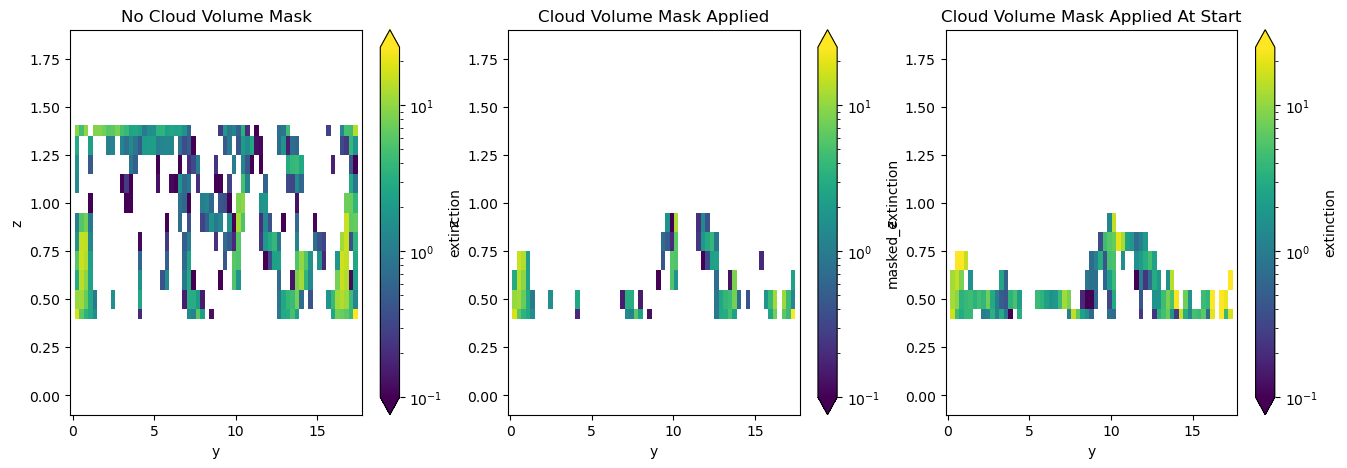

In [4]:
vmin = 0.1
vmax = 25
f, ax = plt.subplots(1, 3, figsize=(16, 5))
cloud02.isel(x=10).extinction.plot(y='z', ax=ax[0], norm=colors.LogNorm(), vmin=vmin, vmax=vmax)
ax[0].set_title('No Cloud Volume Mask')
cloud02.isel(x=10).masked_extinction.plot(y='z', ax=ax[1], norm=colors.LogNorm(), vmin=vmin, vmax=vmax)
ax[1].set_title('Cloud Volume Mask Applied')
cloud03.isel(x=10).extinction.plot(y='z', ax=ax[2], norm=colors.LogNorm(), vmin=vmin, vmax=vmax)
ax[2].set_title('Cloud Volume Mask Applied At Start')

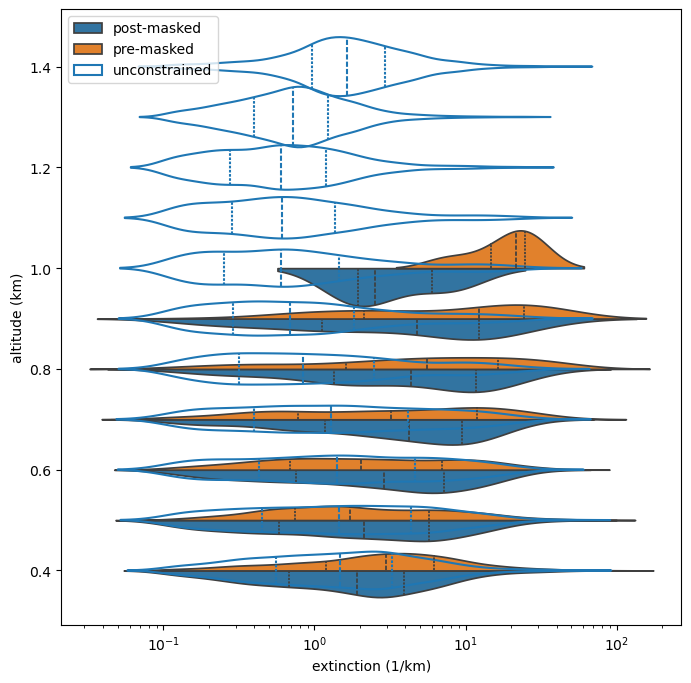

In [57]:
threshold = 0.1
f, ax = plt.subplots(1, 1, figsize=(8, 8))

ext02 = cloud02.extinction.copy(deep=True).data
ext02[ext02 < threshold] = np.nan
ext02_flat = ext02.reshape(-1, ext02.shape[-1])

ext02_masked = cloud02.masked_extinction.copy(deep=True).data
ext02_masked[ext02_masked < threshold] = np.nan
ext02_masked_flat = ext02_masked.reshape(-1, ext02_masked.shape[-1])

ext03 = cloud03.extinction.copy(deep=True).data
ext03[ext03 < threshold] = np.nan
ext03_flat = ext03.reshape(-1, ext03.shape[-1])

# Create a DataFrame with the extinction values and their corresponding levels
levels = np.tile(cloud02.z.data, ext02_masked_flat.shape[0])
data = pd.DataFrame({
    'extinction (1/km)': np.concatenate([ext02_flat.flatten(), ext02_masked_flat.flatten(), ext03_flat.flatten()]),
    'altitude (km)': np.concatenate([levels, levels, levels]),
    'dataset': ['unconstrained'] * ext02_flat.size + ['post-masked'] * ext02_masked_flat.size + ['pre-masked'] * ext03_flat.size
})

# filtered_data = data[(data['altitude (km)'] >= 0.3) & (data['altitude (km)'] <= 1.1) & (data['dataset'] != 'unconstrained')]
filtered_data = data[(data['dataset'] != 'unconstrained')]

# Plot using seaborn violinplot
sns.violinplot(x='extinction (1/km)', y='altitude (km)', hue='dataset', data=filtered_data, split=True, ax=ax, log_scale=(True, False), orient='h', inner='quart', native_scale=True, width=15.0)

filtered_data = data[(data['dataset'] == 'unconstrained')]

# Plot using seaborn violinplot
sns.violinplot(x='extinction (1/km)', y='altitude (km)', hue='dataset', data=filtered_data, split=False, ax=ax, log_scale=(True, False), orient='h', inner='quart', native_scale=True, width=12.0, fill=False)


# ax.set_ylim([0.3, 1.1])
ax.legend(loc='upper left')
# plt.show()